In [68]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")

In [69]:
df = pd.read_csv("Mall_Customers.csv")
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [70]:
df.shape

(200, 5)

In [71]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [72]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [73]:
df.isnull().sum()

,0
CustomerID,0
Gender,0
Age,0
Annual Income (k$),0
Spending Score (1-100),0


In [74]:
df.duplicated().sum()

np.int64(0)

In [75]:
df = df.drop_duplicates()

## Duplicate Records

The dataset contains no duplicate records, so no duplicate removal was required.

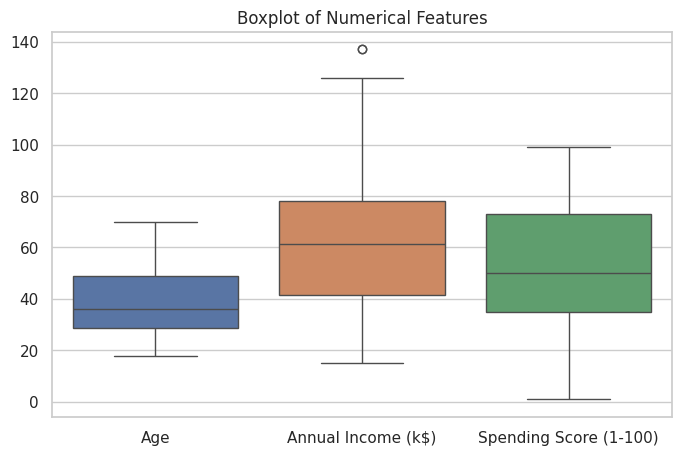

In [76]:
plt.figure(figsize=(8,5))

sns.boxplot(data=df[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']])

plt.title("Boxplot of Numerical Features")

plt.show()

### Outlier Analysis

The boxplot does not show any significant outliers in the numerical features. The data appears consistent and suitable for further analysis, so no outlier removal was required.

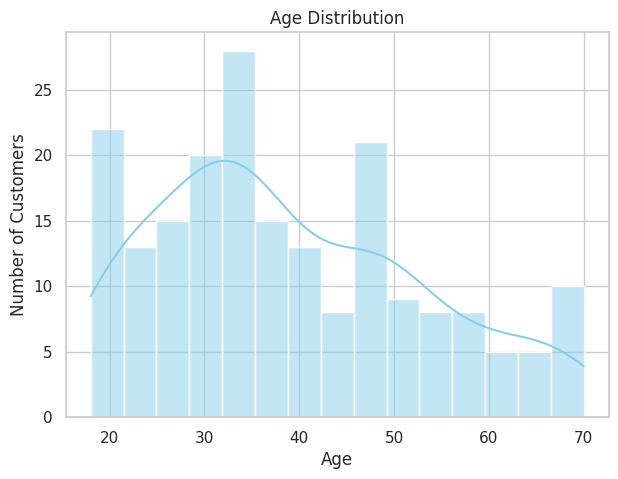

In [77]:
plt.figure(figsize=(7,5))

sns.histplot(df['Age'], bins=15, kde=True, color='skyblue')

plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Customers")

plt.show()

### Age Distribution

The histogram shows that most customers are between 20 and 40 years old, indicating that young and middle-aged adults make up the largest customer group.

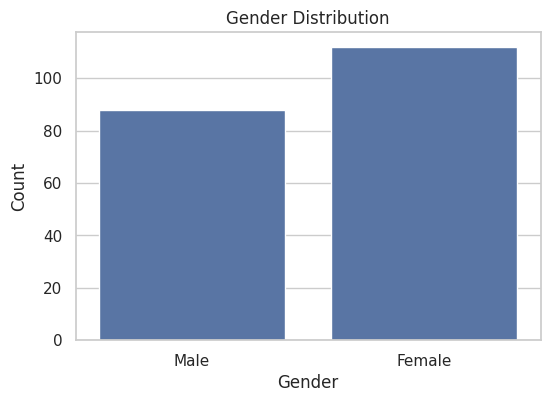

In [78]:
plt.figure(figsize=(6,4))

sns.countplot(x='Gender', data=df)

plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Count")

plt.show()

### Gender Distribution

The dataset contains a nearly equal number of male and female customers, making it balanced for gender-based analysis.

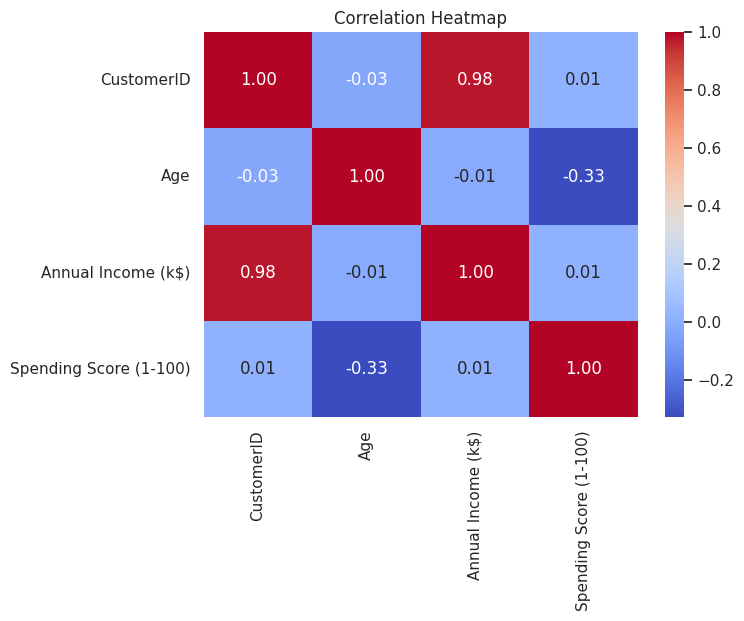

In [79]:
plt.figure(figsize=(7,5))

sns.heatmap(df.corr(numeric_only=True),
            annot=True,
            cmap='coolwarm',
            fmt=".2f")

plt.title("Correlation Heatmap")

plt.show()

### Correlation Analysis

The numerical variables show weak correlations with each other. This suggests that annual income, age, and spending score vary relatively independently.

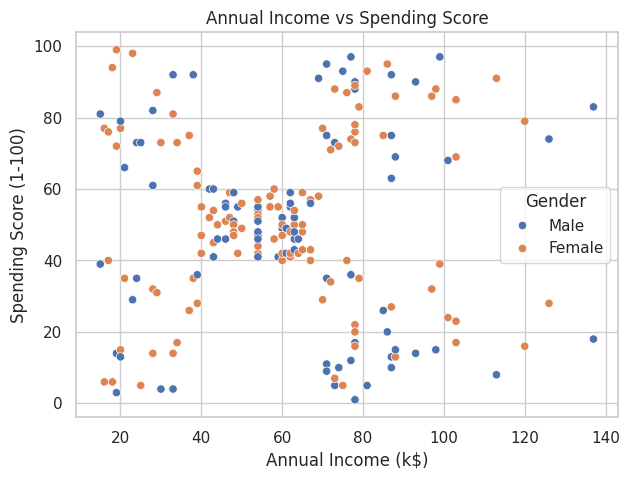

In [80]:
plt.figure(figsize=(7,5))

sns.scatterplot(
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue='Gender',
    data=df
)

plt.title("Annual Income vs Spending Score")

plt.show()

### Income vs Spending Score

Customers with similar annual incomes often have very different spending scores, indicating that income alone does not determine spending behavior.

In [81]:
df["Age Group"] = pd.cut(
    df["Age"],
    bins=[18,30,45,60,80],
    labels=["Young","Adult","Middle Age","Senior"]
)

df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Age Group
0,1,Male,19,15,39,Young
1,2,Male,21,15,81,Young
2,3,Female,20,16,6,Young
3,4,Female,23,16,77,Young
4,5,Female,31,17,40,Adult


In [82]:
df["Income Level"] = pd.cut(
    df["Annual Income (k$)"],
    bins=[0,40,70,140],
    labels=["Low","Medium","High"]
)

df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Age Group,Income Level
0,1,Male,19,15,39,Young,Low
1,2,Male,21,15,81,Young,Low
2,3,Female,20,16,6,Young,Low
3,4,Female,23,16,77,Young,Low
4,5,Female,31,17,40,Adult,Low


In [83]:
df.head(10)

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Age Group,Income Level
0,1,Male,19,15,39,Young,Low
1,2,Male,21,15,81,Young,Low
2,3,Female,20,16,6,Young,Low
3,4,Female,23,16,77,Young,Low
4,5,Female,31,17,40,Adult,Low
5,6,Female,22,17,76,Young,Low
6,7,Female,35,18,6,Adult,Low
7,8,Female,23,18,94,Young,Low
8,9,Male,64,19,3,Senior,Low
9,10,Female,30,19,72,Young,Low


# Key Insights

1. The dataset contains 200 customer records with no missing values or duplicate records.

2. Most customers are between 20 and 40 years old.

3. Annual Income and Spending Score have a weak correlation, suggesting that income alone does not predict customer spending.

4. The dataset has a balanced representation of male and female customers.

5. The engineered features, **Age Group** and **Income Level**, make customer segmentation easier and can improve the performance of future machine learning models.

In [84]:
df.to_csv("Cleaned_Mall_Customers.csv", index=False)